# Supervised Learning

In [29]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import shap
from torch import nn
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, r2_score
from sklearn.model_selection import LeaveOneOut, train_test_split
from sklearn.preprocessing import StandardScaler

sys.path.append("..")
from src.model import StellarCollapseMLP


In [30]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"Using device: {device}")


Using device: mps


In [31]:
RANDOM_SEED = 42

## Data split

Gold has 187 progenitors and 44 pre-collapse features. The stratified split assigns 140 progenitors to training and 47 to test.

In [32]:
gold = pd.read_csv("../data/gold/progenitor_gold.csv")
X = gold.drop(columns=["model", "target_score"])
y = gold["target_score"]

print(f"Progenitors: {len(gold)}")
print(f"Input features: {X.shape[1]}")


Progenitors: 187
Input features: 44


In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_SEED
)

print(f"Train: {len(X_train)} progenitors")
print(f"Test: {len(X_test)} progenitors")

score_counts = pd.DataFrame({
    "all": y.value_counts().sort_index(),
    "train": y_train.value_counts().sort_index(),
    "test": y_test.value_counts().sort_index(),
})
display(score_counts)


Train: 140 progenitors
Test: 47 progenitors


,all,train,test
target_score,,,
0.0,74,56,18
0.2,8,6,2
0.5,20,15,5
0.7,3,2,1
0.8,7,5,2
1.0,75,56,19


## Leave-One-Out validation

The 140 training progenitors form 140 folds, with one progenitor held out in each fold.

In [34]:
loo = LeaveOneOut()
print(f"Leave-One-Out folds: {loo.get_n_splits(X_train)}")

Leave-One-Out folds: 140


## Training one fold

The scaler and network are fitted again with the 139 training progenitors in each fold.

In [35]:
def train_one_fold(X_data, y_data, train_idx, val_idx, hidden_sizes=(32,), loss=nn.BCEWithLogitsLoss(), learning_rate=0.001, epochs=100, device="cpu", record_history=False):
    X_fold_train = X_data.iloc[train_idx]
    X_fold_val = X_data.iloc[val_idx]
    y_fold_train = y_data.iloc[train_idx]
    y_fold_val = y_data.iloc[val_idx]

    scaler = StandardScaler()
    X_fold_train = torch.tensor(scaler.fit_transform(X_fold_train), dtype=torch.float32, device=device)
    X_fold_val = torch.tensor(scaler.transform(X_fold_val), dtype=torch.float32, device=device)
    y_fold_train = torch.tensor(y_fold_train.to_numpy(), dtype=torch.float32, device=device).reshape(-1, 1)
    y_fold_val = torch.tensor(y_fold_val.to_numpy(), dtype=torch.float32, device=device).reshape(-1, 1)

    model = StellarCollapseMLP(X_fold_train.shape[1], hidden_sizes).to(device)
    loss_fn = loss
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    train_losses = []
    val_losses = []
    for _ in range(epochs):
        model.train()
        optimizer.zero_grad()
        logits = model(X_fold_train)
        train_loss = loss_fn(logits, y_fold_train)
        train_loss.backward()
        optimizer.step()

        if record_history:
            model.eval()
            with torch.no_grad():
                train_losses.append(loss_fn(model(X_fold_train), y_fold_train).item())
                val_losses.append(loss_fn(model(X_fold_val), y_fold_val).item())

    model.eval()
    with torch.no_grad():
        logits = model(X_fold_val)
        val_loss = loss_fn(logits, y_fold_val)
        prediction = torch.sigmoid(logits)

    if record_history:
        return val_loss.item(), prediction.item(), train_losses, val_losses
    return val_loss.item(), prediction.item()


## BCE architecture comparison

The table compares hidden layer sizes and training epochs using mean validation BCE and mean absolute error. Standard deviations describe the 140 held-out results.

In [36]:
architectures = [(8,), (16,), (32,), (64,), 
                 (32, 16), (64, 32), (64, 32, 16), 
                 (64, 32, 8),(64, 32, 16, 8)]
epoch_options = [50, 100, 150, 200]

results = []
for hidden_sizes in architectures:
    for epochs in epoch_options:
        torch.manual_seed(RANDOM_SEED)
        fold_losses = []
        fold_errors = []

        for train_idx, val_idx in loo.split(X_train):
            val_loss, prediction = train_one_fold(
                X_train, y_train, train_idx, val_idx,
                hidden_sizes=hidden_sizes, epochs=epochs, device=device
            )
            target = y_train.iloc[val_idx[0]]
            fold_losses.append(val_loss)
            fold_errors.append(abs(prediction - target))

        results.append({
            "hidden_sizes": hidden_sizes,
            "epochs": epochs,
            "mean_val_bce": np.mean(fold_losses),
            "std_val_bce": np.std(fold_losses),
            "mean_absolute_error": np.mean(fold_errors),
            "std_absolute_error": np.std(fold_errors),
        })

grid_results = pd.DataFrame(results)
display(grid_results.sort_values("mean_val_bce", ignore_index=True).round(4))


,hidden_sizes,epochs,mean_val_bce,std_val_bce,mean_absolute_error,std_absolute_error
0,"(32,)",150,0.4141,0.7198,0.1913,0.2100
1,"(32,)",100,0.4251,0.4757,0.2277,0.2090
2,"(32,)",200,0.4278,1.0200,0.1678,0.2097
3,"(32, 16)",150,0.4566,1.4583,0.1562,0.2129
4,"(32, 16)",100,0.4683,0.9920,0.2158,0.2152
5,"(8,)",200,0.4691,0.7252,0.2340,0.2110
6,"(32,)",50,0.4754,0.4245,0.2677,0.2089
7,"(64, 32)",100,0.4818,1.4939,0.1542,0.2156
8,"(64, 32)",50,0.4864,0.7126,0.2474,0.2192
9,"(64, 32)",200,0.4877,1.6982,0.1080,0.2040


## Loss curves

Mean train and validation BCE across the 140 folds. The dashed line marks three consecutive epochs without a validation BCE decrease of at least 0.0001 per epoch.

In [37]:
def plot_loss_curves(train_losses, val_losses, title="Leave-One-Out loss curves", save_name=None):
    epochs = range(1, len(train_losses) + 1)
    small_changes = 0
    low_improvement_epoch = None

    for i in range(1, len(val_losses)):
        improvement = val_losses[i - 1] - val_losses[i]
        if improvement < 0.0001:
            small_changes += 1
        else:
            small_changes = 0

        if small_changes == 3:
            low_improvement_epoch = i + 1
            break

    minimum_epoch = int(np.argmin(val_losses)) + 1
    minimum_loss = val_losses[minimum_epoch - 1]

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, train_losses, label="Train")
    plt.plot(epochs, val_losses, label="Validation")
    if low_improvement_epoch is not None:
        low_improvement_loss = val_losses[low_improvement_epoch - 1]
        plt.axhline(low_improvement_loss, color="gray", linestyle="--", label=f"Low improvement near epoch {low_improvement_epoch}")
        plt.scatter(low_improvement_epoch, low_improvement_loss, color="gray")
        print(f"Low improvement near epoch {low_improvement_epoch}")
    plt.scatter(minimum_epoch, minimum_loss, color="red", marker="x", s=80, label=f"Minimum at epoch {minimum_epoch}")
    print(f"Minimum validation BCE: {minimum_loss:.4f} at epoch {minimum_epoch}")
    plt.xlabel("Epoch")
    plt.ylabel("Mean BCE loss")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    if save_name:
        plt.savefig(f"../docs/figures/{save_name}", dpi=300, bbox_inches="tight")
    plt.show()


## Longer training runs

Train and validation BCE over 500 epochs for five selected architectures.

Low improvement near epoch 132
Minimum validation BCE: 0.4132 at epoch 132


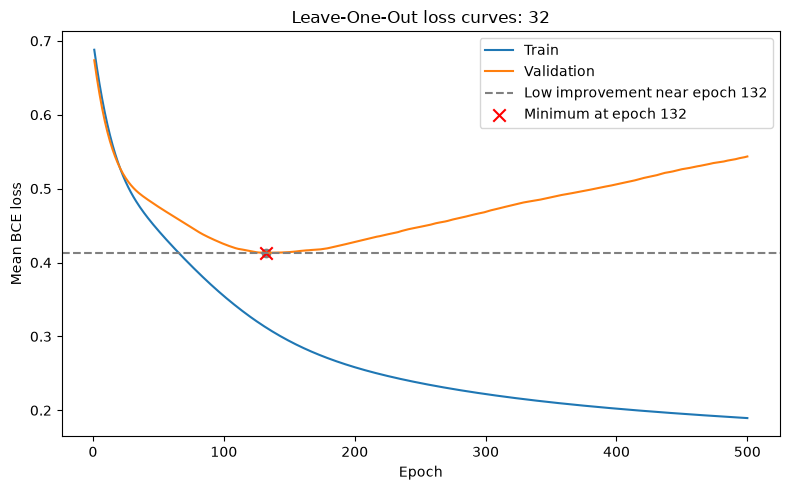

Low improvement near epoch 71
Minimum validation BCE: 0.5231 at epoch 70


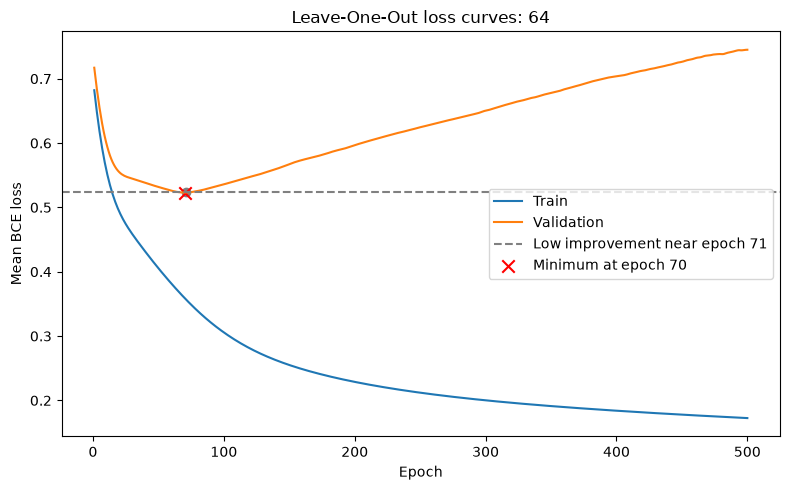

Low improvement near epoch 81
Minimum validation BCE: 0.4660 at epoch 78


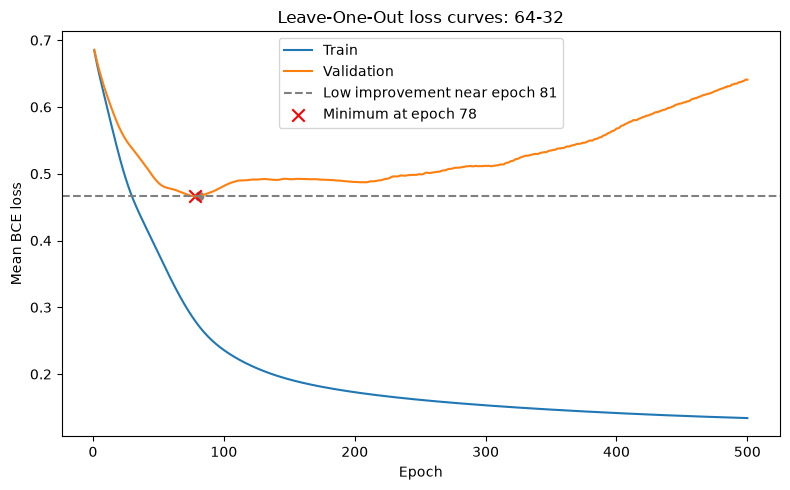

Low improvement near epoch 73
Minimum validation BCE: 0.4896 at epoch 71


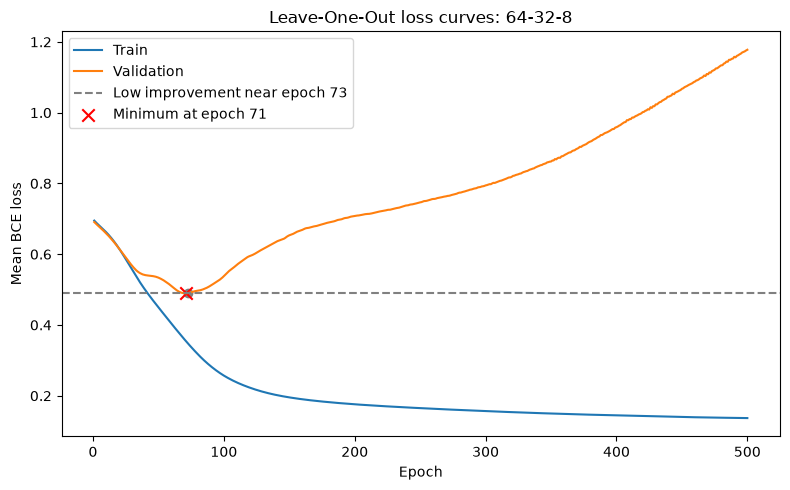

Low improvement near epoch 85
Minimum validation BCE: 0.4815 at epoch 82


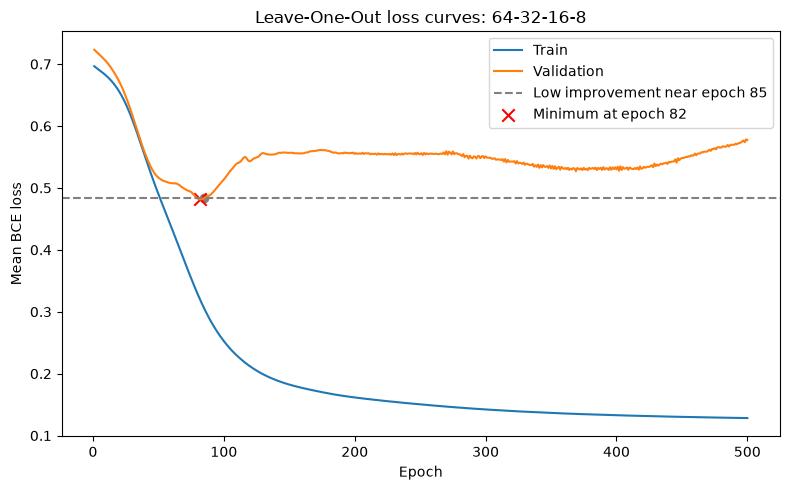

In [38]:
selected_architectures = [(32,), (64,), (64, 32), (64, 32, 8), (64, 32, 16, 8)]

for hidden_sizes in selected_architectures:
    architecture_train_curves = []
    architecture_val_curves = []
    torch.manual_seed(RANDOM_SEED)

    for train_idx, val_idx in loo.split(X_train):
        _, _, train_losses, val_losses = train_one_fold(
            X_train, y_train, train_idx, val_idx,
            hidden_sizes=hidden_sizes, epochs=500, device=device,
            record_history=True
        )
        architecture_train_curves.append(train_losses)
        architecture_val_curves.append(val_losses)

    layer_sizes = "-".join(str(size) for size in hidden_sizes)
    plot_loss_curves(
        np.mean(architecture_train_curves, axis=0),
        np.mean(architecture_val_curves, axis=0),
        title=f"Leave-One-Out loss curves: {layer_sizes}",
        save_name=f"validation_curves_{layer_sizes.replace('-', '_')}.png"
    )


## Selected configuration

The 32-neuron model has the lowest mean validation BCE: 0.4132 at epoch 132. After that, validation BCE rises while train BCE keeps falling. The larger networks reach higher validation minima.

Low improvement near epoch 132
Minimum validation BCE: 0.4132 at epoch 132


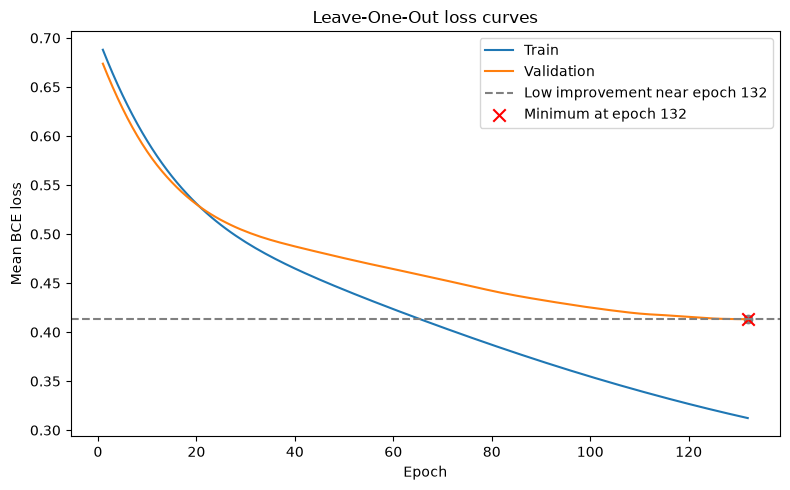

In [39]:
FINAL_HIDDEN_SIZES = (32,)
FINAL_EPOCHS = 132
train_curves = []
val_curves = []
loo_predictions = []

torch.manual_seed(RANDOM_SEED)
for train_idx, val_idx in loo.split(X_train):
    _, prediction, train_losses, val_losses = train_one_fold(
        X_train, y_train, train_idx, val_idx,
        hidden_sizes=FINAL_HIDDEN_SIZES,
        epochs=FINAL_EPOCHS, device=device, record_history=True
    )
    train_curves.append(train_losses)
    val_curves.append(val_losses)
    loo_predictions.append(prediction)

plot_loss_curves(np.mean(train_curves, axis=0), np.mean(val_curves, axis=0),
                 save_name="validation_curves_final_32.png")


## Predicted vs target score

The diagonal shows exact agreement. R² is calculated from the 140 Leave-One-Out predictions.

Leave-One-Out R²: 0.5902


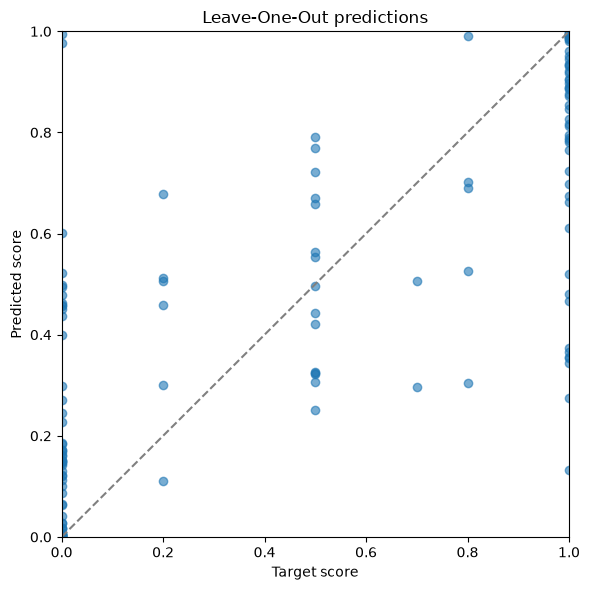

In [40]:
r2 = r2_score(y_train, loo_predictions)
print(f"Leave-One-Out R²: {r2:.4f}")

plt.figure(figsize=(6, 6))
plt.scatter(y_train, loo_predictions, alpha=0.6)
plt.plot([0, 1], [0, 1], color="gray", linestyle="--")
plt.xlabel("Target score")
plt.ylabel("Predicted score")
plt.title("Leave-One-Out predictions")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.tight_layout()
plt.savefig("../docs/figures/loo_predictions.png", dpi=300, bbox_inches="tight")
plt.show()


### Validation predictions

The predictions follow the target direction overall, but some scores of 0 are predicted high and some scores of 1 are predicted low. The intermediate targets are also spread out.

## Final model

In [41]:
torch.manual_seed(RANDOM_SEED)
scaler = StandardScaler()
X_final_train = torch.tensor(scaler.fit_transform(X_train), dtype=torch.float32, device=device)
y_final_train = torch.tensor(y_train.to_numpy(), dtype=torch.float32, device=device).reshape(-1, 1)

final_model = StellarCollapseMLP(X_train.shape[1], FINAL_HIDDEN_SIZES).to(device)
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(final_model.parameters(), lr=0.001)

final_model.train()
for _ in range(FINAL_EPOCHS):
    optimizer.zero_grad()
    loss = loss_fn(final_model(X_final_train), y_final_train)
    loss.backward()
    optimizer.step()

final_model.eval()
print(f"Final model: {FINAL_HIDDEN_SIZES}, {FINAL_EPOCHS} epochs")

Final model: (32,), 132 epochs


In [42]:
model_path = Path("../models/stellar_collapse_mlp.pt")
model_path.parent.mkdir(exist_ok=True)

torch.save({
    "state_dict": {name: value.cpu() for name, value in final_model.state_dict().items()},
    "hidden_sizes": FINAL_HIDDEN_SIZES,
    "feature_names": X_train.columns.tolist(),
    "scaler_mean": scaler.mean_.tolist(),
    "scaler_scale": scaler.scale_.tolist(),
    "threshold": 0.5,
}, model_path)
print(f"Saved model: {model_path}")

Saved model: ../models/stellar_collapse_mlp.pt


## Test results

The final model is evaluated on the 47 held-out progenitors.

Test BCE: 0.3605
Test MAE: 0.1998
Test RMSE: 0.2726
Test R²: 0.6376


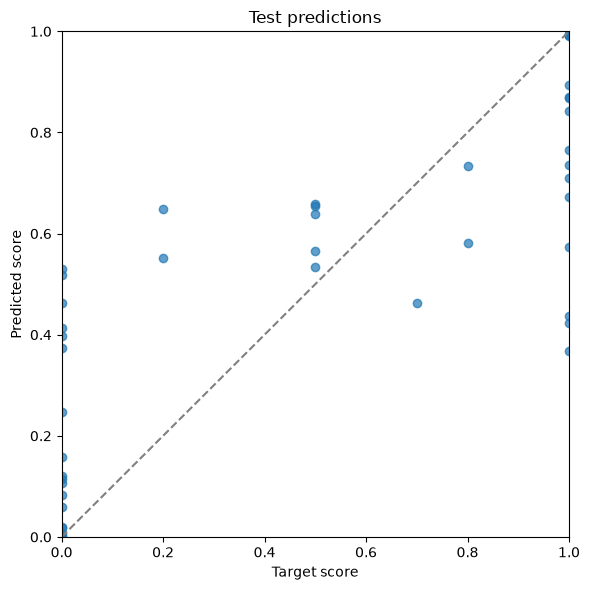

In [43]:
X_final_test = torch.tensor(scaler.transform(X_test), dtype=torch.float32, device=device)
y_final_test = torch.tensor(y_test.to_numpy(), dtype=torch.float32, device=device).reshape(-1, 1)

with torch.no_grad():
    test_logits = final_model(X_final_test)
    test_bce = loss_fn(test_logits, y_final_test).item()
    test_scores = torch.sigmoid(test_logits).cpu().numpy().ravel()

test_mae = np.mean(np.abs(test_scores - y_test.to_numpy()))
test_rmse = np.sqrt(np.mean((test_scores - y_test.to_numpy()) ** 2))
test_r2 = r2_score(y_test, test_scores)
print(f"Test BCE: {test_bce:.4f}")
print(f"Test MAE: {test_mae:.4f}")
print(f"Test RMSE: {test_rmse:.4f}")
print(f"Test R²: {test_r2:.4f}")

plt.figure(figsize=(6, 6))
plt.scatter(y_test, test_scores, alpha=0.7)
plt.plot([0, 1], [0, 1], color="gray", linestyle="--")
plt.xlabel("Target score")
plt.ylabel("Predicted score")
plt.title("Test predictions")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.tight_layout()
plt.savefig("../docs/figures/test_predictions.png", dpi=300, bbox_inches="tight")
plt.show()

### Test predictions

Several points are close to the diagonal, but there are also large errors for target scores 0 and 1.

## Feature importance

Each dot represents one of the 47 test progenitors. Its horizontal position is the signed SHAP contribution to the BH score: left lowers it and right raises it. Color shows the feature value, from low (blue) to high (pink). Features are ranked by mean absolute SHAP impact, but the individual contributions are not averaged in the plot.

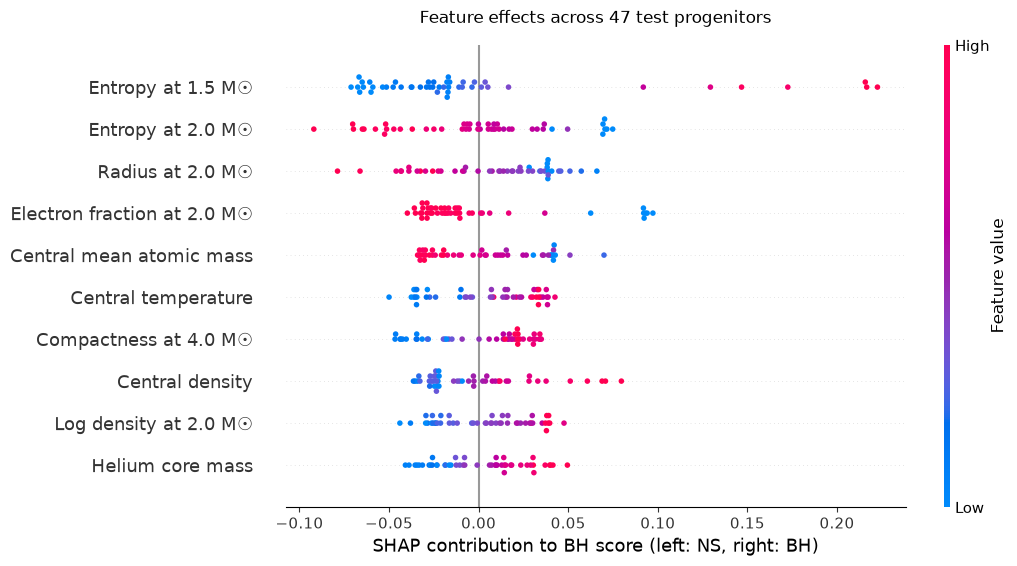

In [44]:
score_model = nn.Sequential(final_model, nn.Sigmoid())
explainer = shap.DeepExplainer(score_model, X_final_train)
shap_values = explainer.shap_values(X_final_test)
vals = shap_values[0] if isinstance(shap_values, list) else shap_values
vals = np.squeeze(vals)
X_test_df = X_test.reset_index(drop=True)

labels = {
    "entropy_at_1p5_msun": "Entropy at 1.5 M☉",
    "entropy_at_2p0_msun": "Entropy at 2.0 M☉",
    "radius_at_2p0_msun_cm": "Radius at 2.0 M☉",
    "ye_at_2p0_msun": "Electron fraction at 2.0 M☉",
    "central_a_bar": "Central mean atomic mass",
    "central_temperature_k": "Central temperature",
    "xi_4p0": "Compactness at 4.0 M☉",
    "central_density_g_cm3": "Central density",
    "log10_density_at_2p0_msun": "Log density at 2.0 M☉",
    "helium_core_mass_msun": "Helium core mass",
}
explanation = shap.Explanation(
    values=vals,
    base_values=np.repeat(np.asarray(explainer.expected_value).item(), len(X_test_df)),
    data=X_test_df.to_numpy(),
    feature_names=[labels.get(name, name) for name in X_test_df.columns],
)
shap.plots.beeswarm(
    explanation, max_display=10, group_remaining_features=False,
    show=False, plot_size=(10, 6)
)
fig = plt.gcf()
ax = plt.gca()
ax.set_xlabel("SHAP contribution to BH score (left: NS, right: BH)")
ax.set_title(f"Feature effects across {len(X_test_df)} test progenitors", pad=16)
plt.savefig("../docs/figures/feature_importance_global.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

report_labels = {
    "entropy_at_1p5_msun": "Entropy, 1.5 M☉",
    "entropy_at_2p0_msun": "Entropy, 2.0 M☉",
    "radius_at_2p0_msun_cm": "Radius, 2.0 M☉",
    "ye_at_2p0_msun": "Electron fraction, 2.0 M☉",
    "central_a_bar": "Central atomic mass",
    "central_temperature_k": "Central temperature",
    "xi_4p0": "Compactness, 4.0 M☉",
    "central_density_g_cm3": "Central density",
    "log10_density_at_2p0_msun": "Log density, 2.0 M☉",
    "helium_core_mass_msun": "Helium core mass",
}
report_explanation = shap.Explanation(
    values=vals, base_values=explanation.base_values, data=explanation.data,
    feature_names=[report_labels.get(name, name) for name in X_test_df.columns],
)
with plt.rc_context({"font.size": 14}):
    shap.plots.beeswarm(
        report_explanation, max_display=10, group_remaining_features=False,
        show=False, plot_size=(7.2, 5.2)
    )
    plt.gca().set_xlabel("Effect on BH score")
    plt.savefig("../docs/figures/feature_importance_report.png", dpi=300, bbox_inches="tight")
    plt.close()

### Feature importance analysis

Entropy at 1.5 M☉ ranks first by mean absolute SHAP impact, followed by entropy at 2.0 M☉. Each dot shows one test progenitor: dots to the right increase its predicted BH consensus score relative to the model's baseline, while dots to the left decrease it. Pink indicates a higher feature value and blue a lower one. In this test set, higher entropy at 1.5 M☉ generally pushes the score toward BH, whereas higher entropy at 2.0 M☉ generally pushes it toward NS. These are patterns in the model's predictions, not causal effects or calibrated physical probabilities.

## Confusion matrix

For this exploratory comparison, scores of 0.5 or higher are assigned to BH, and lower scores to NS. A target score of 0.5 is a weighted tie between engines. I assign that tie to BH by convention.

Accuracy: 0.83


,precision,recall,f1-score,support
NS,0.80,0.80,0.80,20.0
BH,0.85,0.85,0.85,27.0


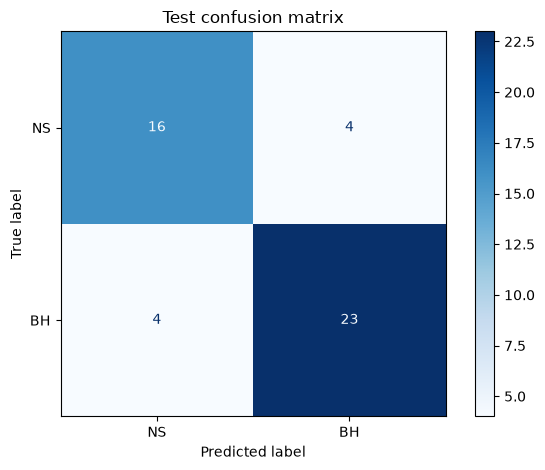

In [45]:
test_true_classes = np.where(y_test.to_numpy() >= 0.5, "BH", "NS")
test_pred_classes = np.where(test_scores >= 0.5, "BH", "NS")

report = classification_report(
    test_true_classes, test_pred_classes, labels=["NS", "BH"],
    output_dict=True, zero_division=0
)
class_metrics = pd.DataFrame({name: report[name] for name in ["NS", "BH"]}).T
print(f"Accuracy: {report['accuracy']:.2f}")
display(class_metrics.round(2))

ConfusionMatrixDisplay.from_predictions(
    test_true_classes, test_pred_classes, labels=["NS", "BH"],
    display_labels=["NS", "BH"], cmap="Blues"
)
plt.title("Test confusion matrix")
plt.tight_layout()
plt.savefig("../docs/figures/confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

## Conclusion

The 32-neuron model reached a mean validation BCE of 0.4132 at epoch 132. On test, BCE was 0.3605, MAE was 0.1998, RMSE was 0.2726 and R² was 0.6376. With the 0.5 cutoff, 39 of 47 labels matched. The target is weighted engine consensus, so these results describe that consensus rather than observed stellar outcomes.